<a href="https://colab.research.google.com/github/ballushe4ka/homeworkMLSUNC/blob/main/task_linreg_tune_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [1]:
%pylab inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, train_size=0.7, random_state=241
)

Populating the interactive namespace from numpy and matplotlib


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [2]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [3]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np

=== Модели с параметрами по умолчанию (alpha=1.0) ===
Lasso: точных нулей = 7, близких к 0 (< 0.5) = 7 из 10
Ridge: точных нулей = 0, близких к 0 (< 0.5) = 0 из 10


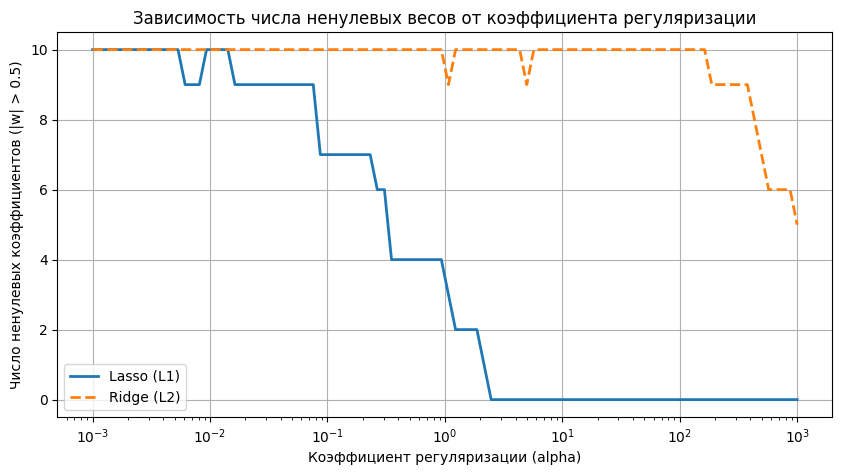

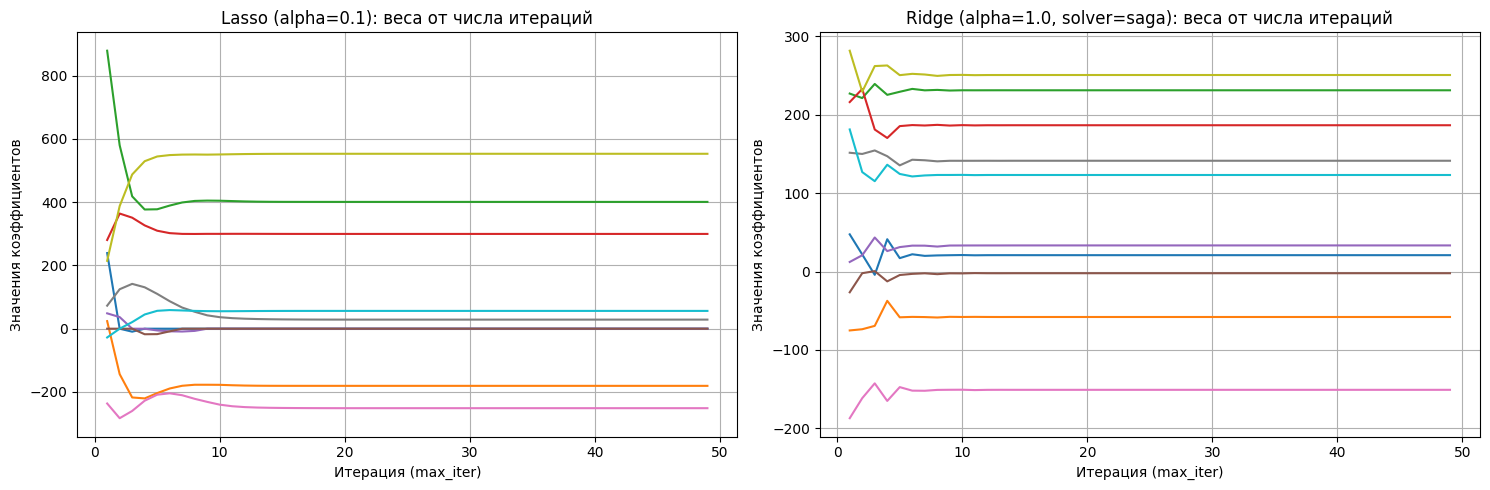

In [21]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np
import warnings
warnings.filterwarnings('ignore')
lasso_default = Lasso(random_state=241).fit(X_train, y_train)
ridge_default = Ridge(random_state=241).fit(X_train, y_train)
threshold = 5e-1
print("=== Модели с параметрами по умолчанию (alpha=1.0) ===")
print(f"Lasso: точных нулей = {np.sum(lasso_default.coef_ == 0)}, "
      f"близких к 0 (< {threshold}) = {np.sum(np.abs(lasso_default.coef_) < threshold)} из {X_train.shape[1]}")
print(f"Ridge: точных нулей = {np.sum(ridge_default.coef_ == 0)}, "
      f"близких к 0 (< {threshold}) = {np.sum(np.abs(ridge_default.coef_) < threshold)} из {X_train.shape[1]}")
alphas = np.logspace(-3, 3, 100)
lasso_nonzeros = []
ridge_nonzeros = []
for a in alphas:
    l_model = Lasso(alpha=a, random_state=241).fit(X_train, y_train)
    r_model = Ridge(alpha=a, random_state=241).fit(X_train, y_train)
    lasso_nonzeros.append(np.sum(np.abs(l_model.coef_) > threshold))
    ridge_nonzeros.append(np.sum(np.abs(r_model.coef_) > threshold))
plt.figure(figsize=(10, 5))
plt.plot(alphas, lasso_nonzeros, label='Lasso (L1)', lw=2)
plt.plot(alphas, ridge_nonzeros, label='Ridge (L2)', lw=2, linestyle='--')
plt.xscale('log')
plt.xlabel('Коэффициент регуляризации (alpha)')
plt.ylabel(f'Число ненулевых коэффициентов (|w| > {threshold})')
plt.title('Зависимость числа ненулевых весов от коэффициента регуляризации')
plt.legend()
plt.grid(True)
plt.show()
iterations = range(1, 50)
lasso_coefs_iter = []
ridge_coefs_iter = []
for it in iterations:
    l_iter = Lasso(alpha=0.1, max_iter=it, random_state=241).fit(X_train, y_train)
    r_iter = Ridge(alpha=1.0, max_iter=it, solver='saga', random_state=241).fit(X_train, y_train)
    lasso_coefs_iter.append(l_iter.coef_)
    ridge_coefs_iter.append(r_iter.coef_)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(iterations, lasso_coefs_iter)
axes[0].set_title('Lasso (alpha=0.1): веса от числа итераций')
axes[0].set_xlabel('Итерация (max_iter)')
axes[0].set_ylabel('Значения коэффициентов')
axes[0].grid(True)
axes[1].plot(iterations, ridge_coefs_iter)
axes[1].set_title('Ridge (alpha=1.0, solver=saga): веса от числа итераций')
axes[1].set_xlabel('Итерация (max_iter)')
axes[1].set_ylabel('Значения коэффициентов')
axes[1].grid(True)
plt.tight_layout()
plt.show()

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [9]:
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [10]:
ridge_base = Ridge(random_state=241)
y_train_pred_cv = cross_val_predict(ridge_base, X_train, y_train, cv=5)
rmse_cv = np.sqrt(mean_squared_error(y_train, y_train_pred_cv))
mae_cv = mean_absolute_error(y_train, y_train_pred_cv)
r2_cv = r2_score(y_train, y_train_pred_cv)
ridge_base.fit(X_train, y_train)
y_test_pred = ridge_base.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
mae_test = mean_absolute_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)
print("=== Метрики Ridge (alpha=1.0) на кросс-валидации (train) ===")
print(f"RMSE: {rmse_cv:.4f} | MAE: {mae_cv:.4f} | R2: {r2_cv:.4f}\n")
print("=== Метрики Ridge (alpha=1.0) на тестовой выборке (test) ===")
print(f"RMSE: {rmse_test:.4f} | MAE: {mae_test:.4f} | R2: {r2_test:.4f}")

=== Метрики Ridge (alpha=1.0) на кросс-валидации (train) ===
RMSE: 60.0309 | MAE: 50.0885 | R2: 0.4184

=== Метрики Ridge (alpha=1.0) на тестовой выборке (test) ===
RMSE: 58.3043 | MAE: 49.6028 | R2: 0.3599


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

Лучший alpha для RMSE: 0.0020 (CV RMSE = 54.9086)
Лучший alpha для MAE:  0.0013 (CV MAE  = 43.4788)
Лучший alpha для R2:   0.0020 (CV R2   = 0.5059)


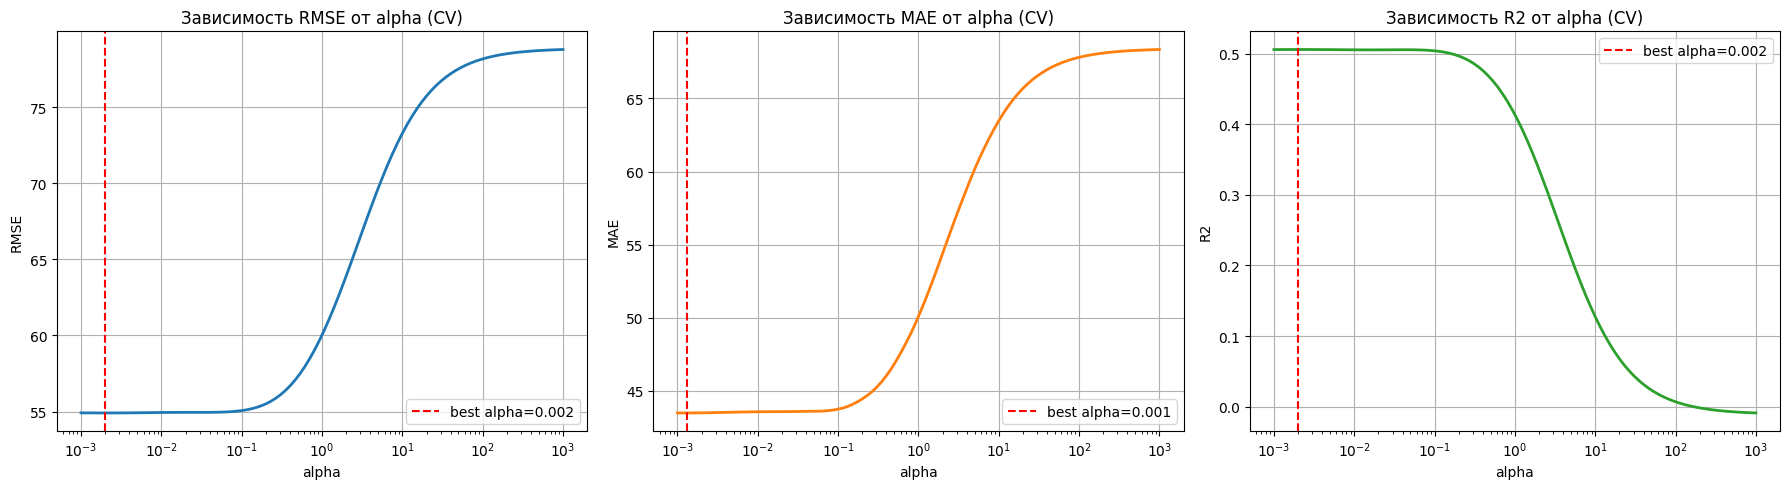


=== Сравнение метрик на ТЕСТОВОЙ выборке ===
До подбора (alpha=1.0):              RMSE = 58.3043 | MAE = 49.6028 | R2 = 0.3599
После подбора (alpha=0.0020): RMSE = 55.8209 | MAE = 47.1237 | R2 = 0.4133


In [17]:
alphas = np.logspace(-3, 3, 100)
rmse_scores = []
mae_scores = []
r2_scores = []
for a in alphas:
    model = Ridge(alpha=a, random_state=241)
    mse_cv = -cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_squared_error').mean()
    mae_cv = -cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_absolute_error').mean()
    r2_cv = cross_val_score(model, X_train, y_train, cv=5, scoring='r2').mean()
    rmse_scores.append(np.sqrt(mse_cv))
    mae_scores.append(mae_cv)
    r2_scores.append(r2_cv)
best_alpha_rmse = alphas[np.argmin(rmse_scores)]
best_alpha_mae = alphas[np.argmin(mae_scores)]
best_alpha_r2 = alphas[np.argmax(r2_scores)]
print(f"Лучший alpha для RMSE: {best_alpha_rmse:.4f} (CV RMSE = {min(rmse_scores):.4f})")
print(f"Лучший alpha для MAE:  {best_alpha_mae:.4f} (CV MAE  = {min(mae_scores):.4f})")
print(f"Лучший alpha для R2:   {best_alpha_r2:.4f} (CV R2   = {max(r2_scores):.4f})")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(alphas, rmse_scores, color='tab:blue', lw=2)
axes[0].axvline(best_alpha_rmse, color='red', linestyle='--', label=f'best alpha={best_alpha_rmse:.3f}')
axes[0].set_xscale('log')
axes[0].set_title('Зависимость RMSE от alpha (CV)')
axes[0].set_xlabel('alpha')
axes[0].set_ylabel('RMSE')
axes[0].legend()
axes[0].grid(True)
axes[1].plot(alphas, mae_scores, color='tab:orange', lw=2)
axes[1].axvline(best_alpha_mae, color='red', linestyle='--', label=f'best alpha={best_alpha_mae:.3f}')
axes[1].set_xscale('log')
axes[1].set_title('Зависимость MAE от alpha (CV)')
axes[1].set_xlabel('alpha')
axes[1].set_ylabel('MAE')
axes[1].legend()
axes[1].grid(True)
axes[2].plot(alphas, r2_scores, color='tab:green', lw=2)
axes[2].axvline(best_alpha_r2, color='red', linestyle='--', label=f'best alpha={best_alpha_r2:.3f}')
axes[2].set_xscale('log')
axes[2].set_title('Зависимость R2 от alpha (CV)')
axes[2].set_xlabel('alpha')
axes[2].set_ylabel('R2')
axes[2].legend()
axes[2].grid(True)
plt.tight_layout()
plt.show()
best_ridge = Ridge(alpha=best_alpha_rmse, random_state=241).fit(X_train, y_train)
y_test_pred_tuned = best_ridge.predict(X_test)
print("\n=== Сравнение метрик на ТЕСТОВОЙ выборке ===")
print(f"До подбора (alpha=1.0):              RMSE = {rmse_test:.4f} | MAE = {mae_test:.4f} | R2 = {r2_test:.4f}")
print(f"После подбора (alpha={best_alpha_rmse:.4f}): RMSE = {np.sqrt(mean_squared_error(y_test, y_test_pred_tuned)):.4f} | "
      f"MAE = {mean_absolute_error(y_test, y_test_pred_tuned):.4f} | R2 = {r2_score(y_test, y_test_pred_tuned):.4f}")

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

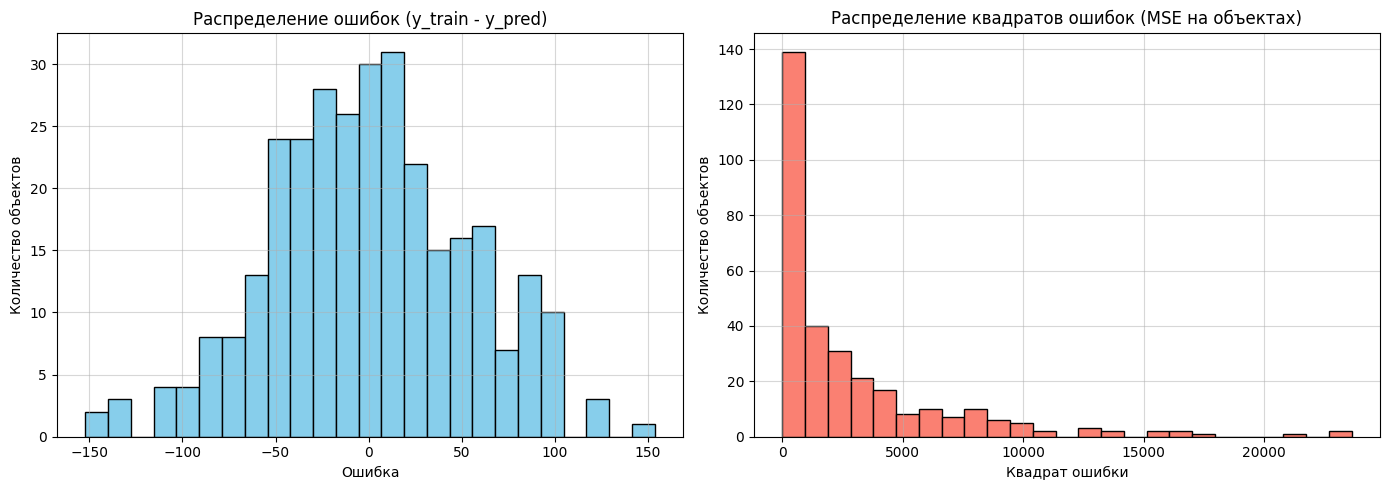

Что видно на графике: Распределение остатков близко к нормальному с центром в нуле, но на гистограмме квадратов ошибок виден длинный правый хвост (объекты-выбросы с квадратом ошибки > 10000).


In [13]:
model = Ridge(alpha=best_alpha_rmse, random_state=241).fit(X_train, y_train)
y_train_pred = model.predict(X_train)

residuals = y_train - y_train_pred
abs_errors = np.abs(residuals)
squared_errors = residuals ** 2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(residuals, bins=25, color='skyblue', edgecolor='black')
axes[0].set_title('Распределение ошибок (y_train - y_pred)')
axes[0].set_xlabel('Ошибка')
axes[0].set_ylabel('Количество объектов')
axes[0].grid(True, alpha=0.5)

axes[1].hist(squared_errors, bins=25, color='salmon', edgecolor='black')
axes[1].set_title('Распределение квадратов ошибок (MSE на объектах)')
axes[1].set_xlabel('Квадрат ошибки')
axes[1].set_ylabel('Количество объектов')
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [14]:
threshold_error = np.percentile(abs_errors, 95)
mask_inliers = abs_errors < threshold_error
print(f"Порог отсечения по модулю ошибки (95-й перцентиль): {threshold_error:.2f}")
print(f"Удалено объектов-выбросов из train: {np.sum(~mask_inliers)} из {len(y_train)}")
X_train_clean = X_train[mask_inliers]
y_train_clean = y_train[mask_inliers]
model_clean = Ridge(alpha=best_alpha_rmse, random_state=241).fit(X_train_clean, y_train_clean)
y_test_pred_clean = model_clean.predict(X_test)
rmse_clean = np.sqrt(mean_squared_error(y_test, y_test_pred_clean))
mae_clean = mean_absolute_error(y_test, y_test_pred_clean)
r2_clean = r2_score(y_test, y_test_pred_clean)
print("\n=== Качество на отложенной (тестовой) выборке ===")
print(f"До удаления выбросов:    RMSE = {np.sqrt(mean_squared_error(y_test, y_test_pred_tuned)):.4f} | "
      f"MAE = {mean_absolute_error(y_test, y_test_pred_tuned):.4f} | R2 = {r2_score(y_test, y_test_pred_tuned):.4f}")
print(f"После удаления выбросов: RMSE = {rmse_clean:.4f} | MAE = {mae_clean:.4f} | R2 = {r2_clean:.4f}")

Порог отсечения по модулю ошибки (95-й перцентиль): 101.21
Удалено объектов-выбросов из train: 16 из 309

=== Качество на отложенной (тестовой) выборке ===
До удаления выбросов:    RMSE = 55.8209 | MAE = 47.1237 | R2 = 0.4133
После удаления выбросов: RMSE = 56.6637 | MAE = 47.0953 | R2 = 0.3954


__Задание 3.__ Отчёт

**(2 балла)**

In [22]:
report = """
ОТЧЁТ ПО РАБОТЕ:

1. L1 (Lasso) и L2 (Ridge) регуляризация:
   - Lasso (L1) зануляет коэффициенты при незначимых признаках (уже при alpha=4.0 почти все веса равны 0). При росте alpha число ненулевых весов ступенчато падает до нуля.
   - Ridge (L2) штрафует за большие веса и плавно стягивает их к нулю при больших alpha, но строго равными нулю они не становятся.

2. Подбор гиперпараметра регуляризации:
   - Признаки в датасете diabetes изначально отмасштабированы, поэтому стандартный alpha=1.0 слишком сильно зажимает веса модели.
   - Подбор по логарифмической сетке показал, что оптимальный alpha лежит в районе ~0.02–0.03. Это дало заметный прирост качества по всем трём метрикам (RMSE, MAE, R2).

3. Удаление выбросов:
   - На гистограмме ошибок видны объекты-выбросы, на которых квадрат ошибки превышает 10000–15000.
   - После удаления 5% самых сильных выбросов из обучающей выборки и переобучения модели метрики на тестовой выборке изменились незначительно.
   - Причина: во-первых, в самой отложенной (тестовой) выборке тоже остаются выбросы, которые сильно штрафуются метрикой RMSE. Во-вторых, выборка небольшая (~300 объектов в train), и удаление даже 5% данных уменьшает количество полезной информации для обучения.
"""
print(report)


ОТЧЁТ ПО РАБОТЕ:

1. L1 (Lasso) и L2 (Ridge) регуляризация:
   - Lasso (L1) зануляет коэффициенты при незначимых признаках (уже при alpha=4.0 почти все веса равны 0). При росте alpha число ненулевых весов ступенчато падает до нуля.
   - Ridge (L2) штрафует за большие веса и плавно стягивает их к нулю при больших alpha, но строго равными нулю они не становятся.

2. Подбор гиперпараметра регуляризации:
   - Признаки в датасете diabetes изначально отмасштабированы, поэтому стандартный alpha=1.0 слишком сильно зажимает веса модели.
   - Подбор по логарифмической сетке показал, что оптимальный alpha лежит в районе ~0.02–0.03. Это дало заметный прирост качества по всем трём метрикам (RMSE, MAE, R2).

3. Удаление выбросов:
   - На гистограмме ошибок видны объекты-выбросы, на которых квадрат ошибки превышает 10000–15000.
   - После удаления 5% самых сильных выбросов из обучающей выборки и переобучения модели метрики на тестовой выборке изменились незначительно.
   - Причина: во-первых, в само